# Notebook 04: Classification via Purely Geometric Curvature Losses ($K < 0$ vs. $K > 0$)

## Research Objective
Can a deep neural network learn to classify a non-linear dataset (`make_moons`) using **only differential geometric objects** in its loss function—without any cross-entropy, MSE, or coordinate-level logit supervision?

We train the **`[2 -> 5 -> 10 -> 15 -> 10 -> 2]`** MLP from scratch by sculpting the intrinsic **Gaussian curvature** $K(x; \theta)$ of the final representation manifold $\mathcal{M}_5$ (equipped with the Graph Embedding Metric $\tilde{g}^{(5)}_{ij}(x) = \delta_{ij} + ((J^{(5)}(x))^T J^{(5)}(x))_{ij}$):
- **Class $0$ ($y = 0, s = -1$)**: Driven into regions of **negative Gaussian curvature** ($K(x) \le -\tau < 0$, hyperbolic saddle geometry).
- **Class $1$ ($y = 1, s = +1$)**: Driven into regions of **positive Gaussian curvature** ($K(x) \ge +\tau > 0$, spherical/elliptic dome geometry).

### Purely Geometric Loss Function
$$\mathcal{L}_{\text{geom}}(\theta) = \frac{1}{N}\sum_{n=1}^N \mathrm{softplus}_\beta\!\Big(\tau - (2y_n - 1)\, K_{\text{clip}}(x_n; \theta)\Big) + \lambda_{\text{vol}} \frac{1}{N}\sum_{n=1}^N \Big(\log \det \tilde{g}^{(5)}(x_n; \theta)\Big)^2 + \lambda_{\text{iso}} \frac{1}{N}\sum_{n=1}^N \|\tilde{g}^{(5)}(x_n; \theta) - I_2\|_F^2$$

- **Requires 3rd-Order Automatic Differentiation**: Since $K(x; \theta)$ depends on $\partial_x^2 g_{ij}(x; \theta)$ (2nd spatial derivatives of $\Phi^{(5)}_\theta$), computing $\nabla_\theta \mathcal{L}_{\text{geom}}(\theta)$ backpropagates through 3rd-order mixed spatio-parametric derivatives $\frac{\partial^3 \Phi^{(5)}_\theta(x)}{\partial \theta \partial x^i \partial x^j}$.
- **Purely Geometric Inference Rule**: At test time, any point $x^*$ is classified strictly by the sign of the local manifold curvature:
  $$\hat{y}(x^*) = \mathbb{I}\big[ K(x^*; \theta) > 0 \big]$$

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "src" / "geometry.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import time
import numpy as np
import torch
import matplotlib.pyplot as plt

from src.geometry import (
    MoonsMLP,
    get_moons_dataset,
    make_evaluation_grid,
    compute_layer_geometry,
    curvature_margin_loss,
)

X_train, y_train, X_test, y_test = get_moons_dataset(n_train=220, n_test=120, noise=0.10, seed=42)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=28, padding=0.45)
print(f"Loaded make_moons | Train: {X_train.shape[0]} pts | Test: {X_test.shape[0]} pts")

Loaded make_moons | Train: 220 pts | Test: 120 pts


## 1. End-to-End 3rd-Order Autodiff Training with Purely Geometric Curvature Loss
We optimize $\mathcal{L}_{\text{geom}}(\theta)$ for 90 epochs with Adam (`lr=0.025`) and margin $\tau = 0.40$, tracking the separation of Gaussian curvature between Class $0$ ($K < 0$) and Class $1$ ($K > 0$).

Epoch   1 ( 0.1s) | Geom Loss: 0.4709 | Train Acc (K>0):  47.7% | Test Acc (K>0):  57.5% | E[K|y=0]: +0.055 | E[K|y=1]: +0.036
Epoch  20 ( 1.2s) | Geom Loss: 0.2828 | Train Acc (K>0):  85.0% | Test Acc (K>0):  91.7% | E[K|y=0]: -0.640 | E[K|y=1]: +0.213
Epoch  45 ( 2.8s) | Geom Loss: 0.1043 | Train Acc (K>0):  95.5% | Test Acc (K>0):  95.8% | E[K|y=0]: -1.003 | E[K|y=1]: +0.925
Epoch  90 ( 5.7s) | Geom Loss: 0.0464 | Train Acc (K>0):  99.5% | Test Acc (K>0):  96.7% | E[K|y=0]: -1.288 | E[K|y=1]: +1.253


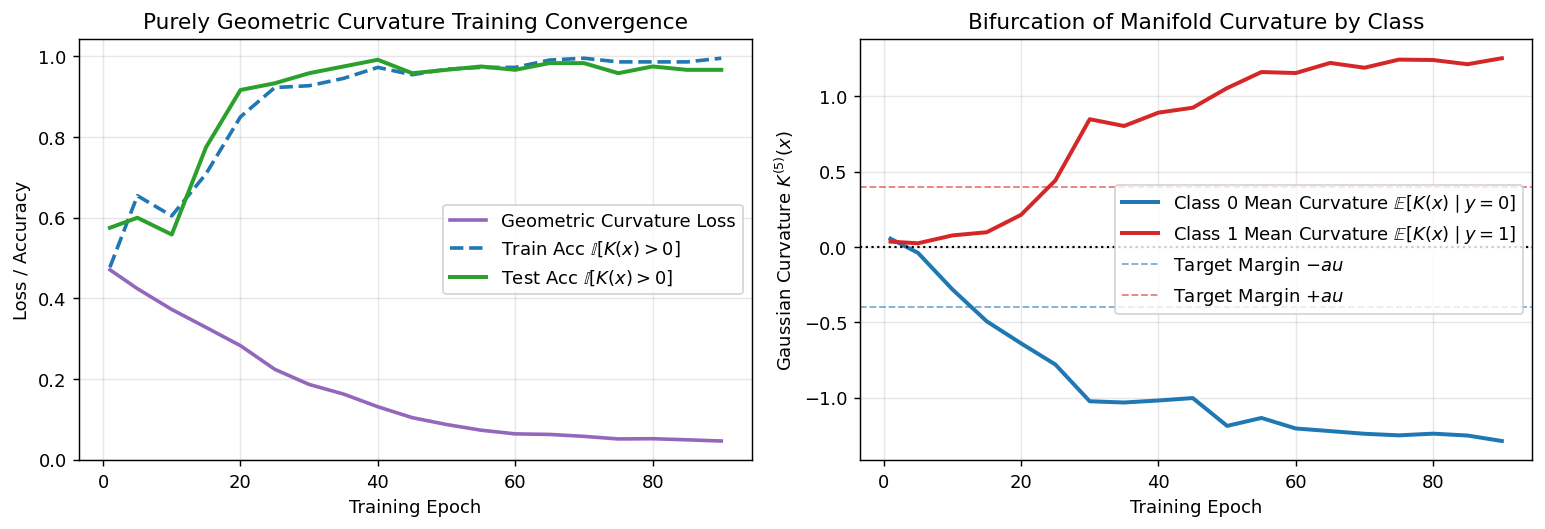

In [2]:
geom_model = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=7)
optimizer = torch.optim.Adam(geom_model.parameters(), lr=0.025)

hist = {
    "epoch": [],
    "loss": [],
    "train_acc": [],
    "test_acc": [],
    "K_c0": [],
    "K_c1": [],
}

t0 = time.time()
for epoch in range(1, 91):
    optimizer.zero_grad()
    params = dict(geom_model.named_parameters())
    geom_tr = compute_layer_geometry(geom_model, X_train, layer_idx=5, metric_mode="graph", params=params)
    loss, metrics = curvature_margin_loss(
        geom_tr["K"],
        y_train,
        geom_tr["g"],
        margin=0.40,
        beta_hinge=4.0,
        lambda_vol=0.02,
        lambda_iso=0.005,
        k_clip=10.0,
    )
    loss.backward()
    torch.nn.utils.clip_grad_norm_(geom_model.parameters(), max_norm=5.0)
    optimizer.step()

    if epoch == 1 or epoch % 5 == 0:
        with torch.no_grad():
            geom_te = compute_layer_geometry(geom_model, X_test, layer_idx=5, metric_mode="graph")
            te_acc = ((geom_te["K"] > 0.0).long() == y_test).float().mean().item()
        hist["epoch"].append(epoch)
        hist["loss"].append(metrics["loss_total"])
        hist["train_acc"].append(metrics["geom_acc"])
        hist["test_acc"].append(te_acc)
        hist["K_c0"].append(metrics["mean_K_class0"])
        hist["K_c1"].append(metrics["mean_K_class1"])

    if epoch in [1, 20, 45, 90]:
        print(
            f"Epoch {epoch:3d} ({time.time()-t0:4.1f}s) | Geom Loss: {metrics['loss_total']:.4f} | "
            f"Train Acc (K>0): {metrics['geom_acc']*100:5.1f}% | Test Acc (K>0): {hist['test_acc'][-1]*100:5.1f}% | "
            f"E[K|y=0]: {metrics['mean_K_class0']:+6.3f} | E[K|y=1]: {metrics['mean_K_class1']:+6.3f}"
        )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(hist["epoch"], hist["loss"], lw=2, color="#9467bd", label="Geometric Curvature Loss")
axes[0].plot(hist["epoch"], hist["train_acc"], lw=2, color="#1f77b4", ls="--", label="Train Acc $\mathbb{I}[K(x)>0]$")
axes[0].plot(hist["epoch"], hist["test_acc"], lw=2.2, color="#2ca02c", label="Test Acc $\mathbb{I}[K(x)>0]$")
axes[0].set_xlabel("Training Epoch")
axes[0].set_ylabel("Loss / Accuracy")
axes[0].set_title("Purely Geometric Curvature Training Convergence")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(hist["epoch"], hist["K_c0"], lw=2.2, color="#1f77b4", label="Class 0 Mean Curvature $\mathbb{E}[K(x) \mid y=0]$")
axes[1].plot(hist["epoch"], hist["K_c1"], lw=2.2, color="#d62728", label="Class 1 Mean Curvature $\mathbb{E}[K(x) \mid y=1]$")
axes[1].axhline(0.0, color="k", lw=1.2, ls=":")
axes[1].axhline(-0.4, color="#1f77b4", lw=1.0, ls="--", alpha=0.6, label="Target Margin $-\tau$")
axes[1].axhline(+0.4, color="#d62728", lw=1.0, ls="--", alpha=0.6, label="Target Margin $+\tau$")
axes[1].set_xlabel("Training Epoch")
axes[1].set_ylabel("Gaussian Curvature $K^{(5)}(x)$")
axes[1].set_title("Bifurcation of Manifold Curvature by Class")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Learned 2D Gaussian Curvature Landscape & Zero-Curvature Decision Boundary ($K(x) = 0$)
We evaluate $K^{(5)}(x)$ over the entire 2D grid and on the held-out test set. Notice how the **zero-curvature contour $K(x) = 0$** forms a smooth geometric boundary separating the hyperbolic negative-curvature valley containing Class $0$ from the positive-curvature elliptic dome containing Class $1$.

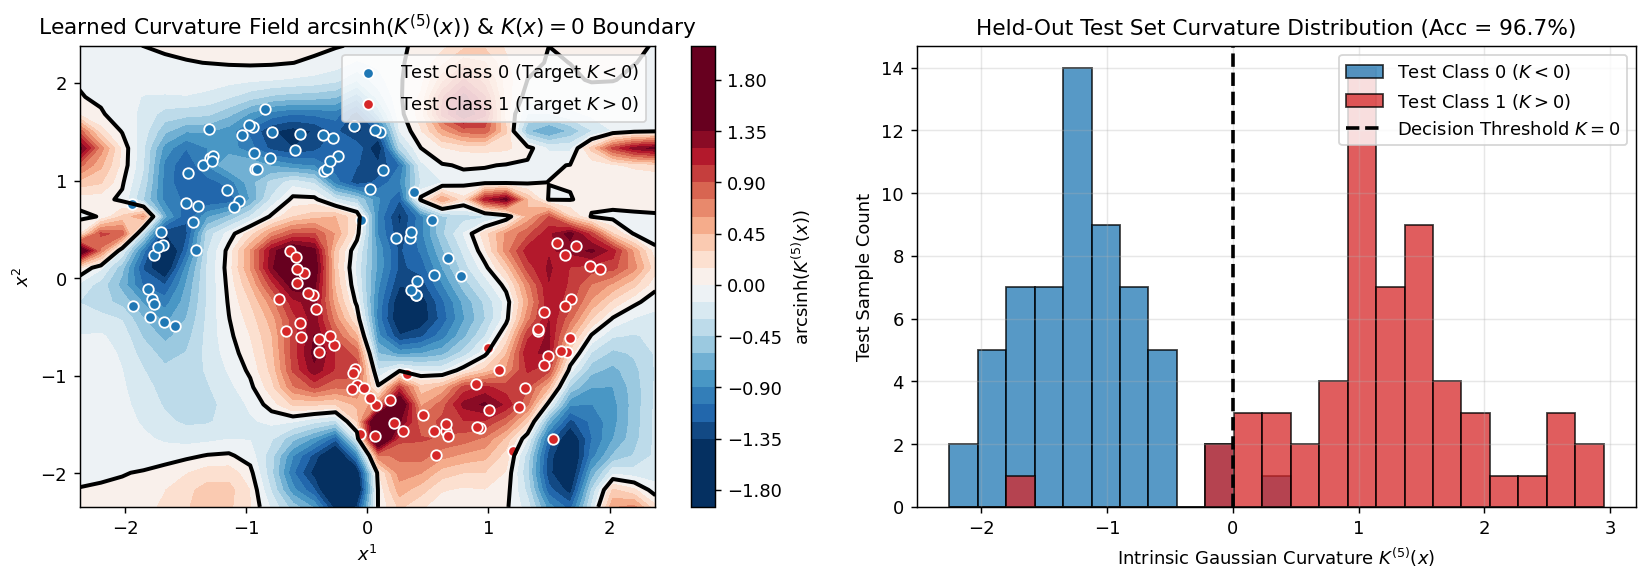

In [3]:
geom_grid = compute_layer_geometry(geom_model, grid_pts, layer_idx=5, metric_mode="graph")
K_grid = geom_grid["K"].detach().numpy().reshape(xx.shape)
K_grid_sinh = np.arcsinh(K_grid)
vmax = max(np.percentile(np.abs(K_grid_sinh), 96), 0.5)

geom_test = compute_layer_geometry(geom_model, X_test, layer_idx=5, metric_mode="graph")
K_test = geom_test["K"].detach().numpy()
y_test_np = y_test.numpy()

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.6))
cf = axes[0].contourf(xx, yy, K_grid_sinh, levels=25, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].contour(xx, yy, K_grid, levels=[0.0], colors="k", linewidths=2.2)
axes[0].scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", edgecolors="w", s=34, label="Test Class 0 (Target $K < 0$)")
axes[0].scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", edgecolors="w", s=34, label="Test Class 1 (Target $K > 0$)")
axes[0].set_title("Learned Curvature Field $\mathrm{arcsinh}(K^{(5)}(x))$ & $K(x)=0$ Boundary")
axes[0].set_xlabel("$x^1$")
axes[0].set_ylabel("$x^2$")
axes[0].legend(loc="upper right")
plt.colorbar(cf, ax=axes[0], label="$\mathrm{arcsinh}(K^{(5)}(x))$")

bins = np.linspace(np.percentile(K_test, 2) - 0.2, np.percentile(K_test, 98) + 0.2, 24)
axes[1].hist(K_test[y_test_np == 0], bins=bins, alpha=0.75, color="#1f77b4", edgecolor="k", label="Test Class 0 ($K < 0$)")
axes[1].hist(K_test[y_test_np == 1], bins=bins, alpha=0.75, color="#d62728", edgecolor="k", label="Test Class 1 ($K > 0$)")
axes[1].axvline(0.0, color="k", lw=2.0, ls="--", label="Decision Threshold $K = 0$")
axes[1].set_xlabel("Intrinsic Gaussian Curvature $K^{(5)}(x)$")
axes[1].set_ylabel("Test Sample Count")
axes[1].set_title(f"Held-Out Test Set Curvature Distribution (Acc = {((K_test > 0) == y_test_np).mean()*100:.1f}%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. 3D Visualization of the Learned Output Surface Coloured by Intrinsic Gaussian Curvature $K(x)$
We visualize the learned graph surface $(x^1, x^2, z^1(x))$ in $\mathbb{R}^3$ coloured by its exact Gaussian curvature $K^{(5)}(x)$, illustrating how the neural network bends the manifold into a saddle ($K < 0$, blue) over Class $0$ and a dome ($K > 0$, red) over Class $1$.

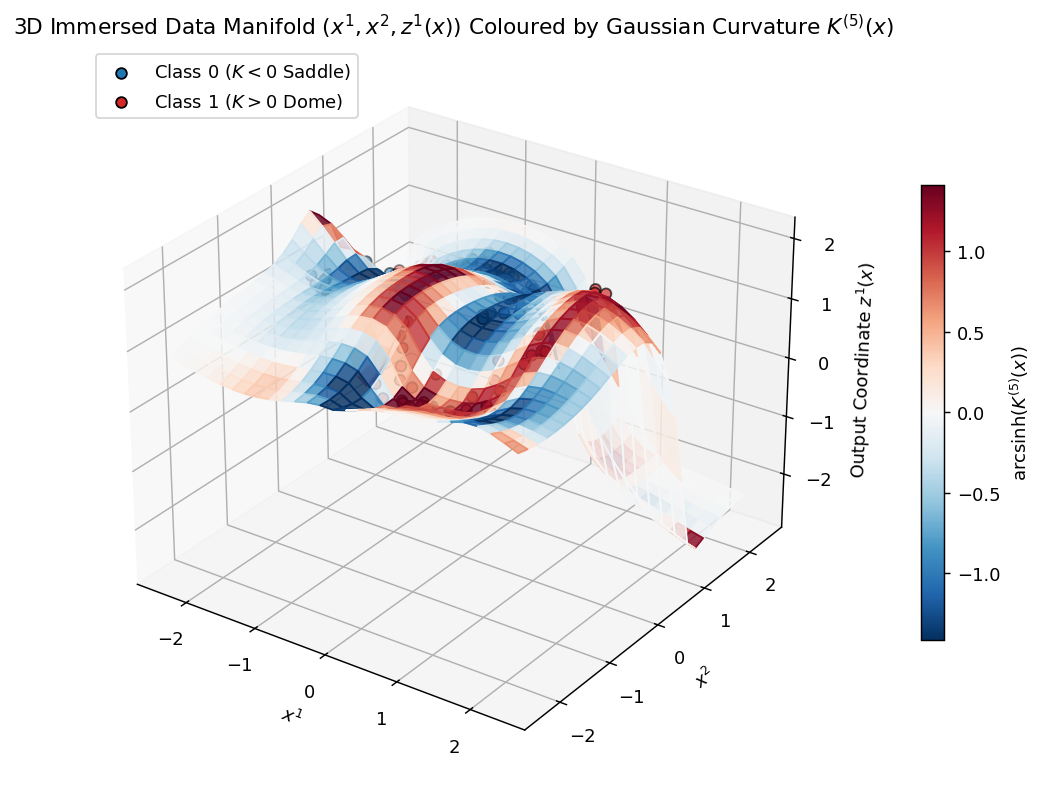

In [4]:
from matplotlib import cm
from matplotlib.colors import Normalize

with torch.no_grad():
    z_grid = geom_model(grid_pts).detach().numpy()
    z_te = geom_model(X_test).detach().numpy()

z1_surf = z_grid[:, 0].reshape(xx.shape)
norm = Normalize(vmin=-vmax, vmax=vmax)
facecolors = cm.RdBu_r(norm(K_grid_sinh))

fig = plt.figure(figsize=(10, 6.2))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(xx, yy, z1_surf, facecolors=facecolors, rstride=1, cstride=1, alpha=0.82, antialiased=True, shade=False)

x_te_np = X_test.numpy()
ax.scatter(x_te_np[y_test_np == 0, 0], x_te_np[y_test_np == 0, 1], z_te[y_test_np == 0, 0] + 0.08, c="#1f77b4", edgecolors="k", s=35, label="Class 0 ($K < 0$ Saddle)")
ax.scatter(x_te_np[y_test_np == 1, 0], x_te_np[y_test_np == 1, 1], z_te[y_test_np == 1, 0] + 0.08, c="#d62728", edgecolors="k", s=35, label="Class 1 ($K > 0$ Dome)")

ax.set_xlabel("$x^1$")
ax.set_ylabel("$x^2$")
ax.set_zlabel("Output Coordinate $z^1(x)$")
ax.set_title("3D Immersed Data Manifold $(x^1, x^2, z^1(x))$ Coloured by Gaussian Curvature $K^{(5)}(x)$")
ax.view_init(elev=28, azim=-55)
ax.legend(loc="upper left")
mappable = cm.ScalarMappable(cmap=cm.RdBu_r, norm=norm)
mappable.set_array(K_grid_sinh)
plt.colorbar(mappable, ax=ax, shrink=0.62, pad=0.08, label="$\mathrm{arcsinh}(K^{(5)}(x))$")
plt.tight_layout()
plt.show()